In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
import numpy as np
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler


In [39]:
df = pd.read_csv ("C:/Users/user/Documents/Master_S1/ML/transactions_TP2.csv")

In [40]:
print(df.head())

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [41]:
print(df.shape)

(3045, 12)


In [42]:
print(df.dtypes)

id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object


In [43]:
null = df.isnull().sum()
pct_null = (null / len(df)) * 100
tableau_null = pd.DataFrame({
    "Nb_valeurs_manquantes": null,
    "Pourcentage(%)": pct_null
})
tableau_null = tableau_null.sort_values(by = "Pourcentage(%)", ascending = False)
print(tableau_null)

                  Nb_valeurs_manquantes  Pourcentage(%)
canal                               159        5.221675
anciennete_mois                     137        4.499179
appareil                            122        4.006568
montant_dh                          110        3.612479
region                              103        3.382594
nb_ops_24h                           53        1.740558
id_operation                          0        0.000000
id_client                             0        0.000000
heure                                 0        0.000000
international                         0        0.000000
resultat_enquete                      0        0.000000
fraude                                0        0.000000


In [44]:
nb_doublons = df["id_operation"].duplicated().sum()
print("Le nombre d'opérations répétées est :", nb_doublons)
df = df.drop_duplicates(subset = "id_operation", keep = "first")
print("Nombre de lignes restantes :", len(df))

Le nombre d'opérations répétées est : 45
Nombre de lignes restantes : 3000


Text(0.5, 0, 'Montant')

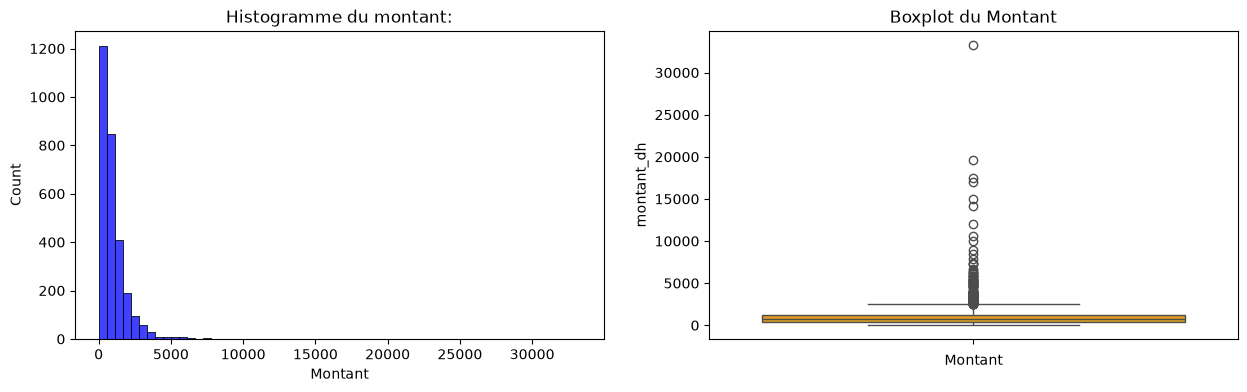

In [45]:
fig, axes = plt.subplots(1, 2, figsize = (15,4))
sns.histplot(df["montant_dh"], bins = 60, ax = axes[0], color = "blue")
axes[0].set_title("Histogramme du montant:")
axes[0].set_xlabel("Montant")

sns.boxplot(df["montant_dh"], ax = axes[1], color = "orange")
axes[1].set_title("Boxplot du Montant")
axes[1].set_xlabel("Montant")

Proportion des fraudes:
 fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


Text(0, 0.5, 'Nombre de transactions')

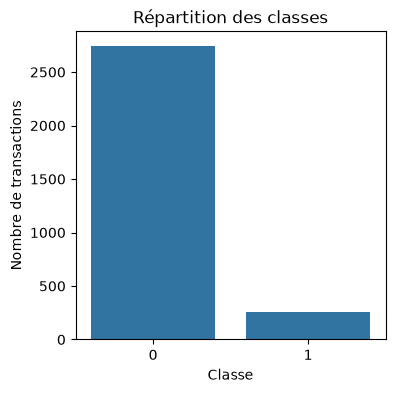

In [46]:
proportion_fraude = (df["fraude"].value_counts(normalize=True) * 100)
print("Proportion des fraudes:\n", proportion_fraude)

plt.figure(figsize = (4, 4))
sns.countplot(x = "fraude", data = df)
plt.title("Répartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")

In [48]:
#Partie 2
colonnes_retirer = ["id_operation", "id_client", "resultat_enquete", "fraude"]
X = df.drop(columns = colonnes_retirer)
y = df["fraude"]

In [49]:
X_ref, X_ver, y_ref, y_ver = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42)
#Aucun classifieur ne sera entraîné
prop_originale = y.mean() * 100
prop_ref = y_ref.mean() * 100
prop_ver = y_ver.mean() * 100
tableau_comparatif = pd.DataFrame({
    "Groupe": ["Originale", "Référence", "Vérification"],
    "Proportion de fraude": [prop_originale, prop_ref, prop_ver]
})
print(tableau_comparatif)

         Groupe  Proportion de fraude
0     Originale              8.600000
1     Référence              8.583333
2  Vérification              8.666667


In [50]:
colonnes_numeriques = X_ref.select_dtypes(include = ["int64", "float64"]).columns.tolist()
print("Variables numériques :", colonnes_numeriques)

colonnes_categorielles = X_ref.select_dtypes(include = ["str", "category"]).columns.tolist()
print("Variables catégorielles :", colonnes_categorielles)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


In [51]:
pipeline_numerique = Pipeline(steps = [
    ("Imputation_mediane", SimpleImputer(strategy = "median")),
    ("Standardisation", StandardScaler())
])
pipeline_numerique.fit(X_ref[colonnes_numeriques])
X_ref_transforme = pipeline_numerique.transform(X_ref[colonnes_numeriques])
X_ver_transforme = pipeline_numerique.transform(X_ver[colonnes_numeriques])

In [52]:
pipeline_categoriel = Pipeline(steps = [
    ("Imputation_frequent", SimpleImputer(strategy = "most_frequent")),
    ("OneHot_Encoder", OneHotEncoder(handle_unknown = "ignore"))
])
X_ref_categor_transforme = pipeline_categoriel.fit_transform(X_ref[colonnes_categorielles])
X_ver_categor_transforme = pipeline_categoriel.transform(X_ver[colonnes_categorielles])


In [53]:
preprocesseur = ColumnTransformer(transformers = [
        ("numerique", pipeline_numerique, colonnes_numeriques),
        ("categoriel", pipeline_categoriel, colonnes_categorielles)
])
X_ref_final = preprocesseur.fit_transform(X_ref)
X_ver_final = preprocesseur.transform(X_ver)

print("Avant la transformation :")
print("- Groupe de référence :", X_ref.shape)
print("- Groupe de vérification :", X_ver.shape)

print("\nAprès la transformation :")
print("- Groupe final de référence :", X_ref_final.shape)
print("- Groupe final de vérification :", X_ver_final.shape)

Avant la transformation :
- Groupe de référence : (2400, 8)
- Groupe de vérification : (600, 8)

Après la transformation :
- Groupe final de référence : (2400, 18)
- Groupe final de vérification : (600, 18)


In [54]:
pipeline_numerique_robuste = Pipeline(steps = [
    ("Imputation_mediane", SimpleImputer(strategy = "median")),
    ("Robust_scaler", RobustScaler())
])

preprocesseur_robuste = ColumnTransformer(transformers = [
        ("numerique", pipeline_numerique_robuste, colonnes_numeriques),
        ("categoriel", pipeline_categoriel, colonnes_categorielles)
])
X_ref_robuste = preprocesseur_robuste.fit_transform(X_ref)

ref_montant = X_ref[["montant_dh"]]
montant_transforme = pipeline_numerique_robuste.fit_transform(ref_montant)
print("Valeurs originales :", ref_montant.head().values.flatten())
print("Valeurs transformées :", montant_transforme[:5].flatten())

index_max = ref_montant["montant_dh"].idxmax()
print("Montant extrême original :", ref_montant.loc[index_max].values)
pos_max = ref_montant.index.get_loc(index_max)
print("Montant extrême transformé :", montant_transforme[pos_max])

Valeurs originales : [ 419.53  533.01  477.87 2518.08  394.74]
Valeurs transformées : [-0.35673954 -0.21774757 -0.28528385  2.21359544 -0.3871027 ]
Montant extrême original : [33281.23]
Montant extrême transformé : [39.89275522]


In [55]:
#Partie 3
Q1 = X_ref["montant_dh"].quantile(0.25)
Q3 = X_ref["montant_dh"].quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 = {Q1}")
print(f"Q3 = {Q3}")
print(f"IQR = {IQR}")

Q1 = 393.095
Q3 = 1249.8775
IQR = 856.7825


In [56]:
L = Q1 - 1.5 * IQR
U = Q3 + 1.5 * IQR
print(f"Borne = [{L}, {U}]")
dehors_borne = X_ref[(X_ref["montant_dh"] < L) | (X_ref["montant_dh"] > U)]
print(f"Nombre de lignes concernées : {len(dehors_borne)}")
print("Afficher quelques cas :")
print(dehors_borne[["montant_dh"]].head())

Borne = [-892.0787499999999, 2535.05125]
Nombre de lignes concernées : 146
Afficher quelques cas :
      montant_dh
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99


Text(0.5, 0, 'Montant')

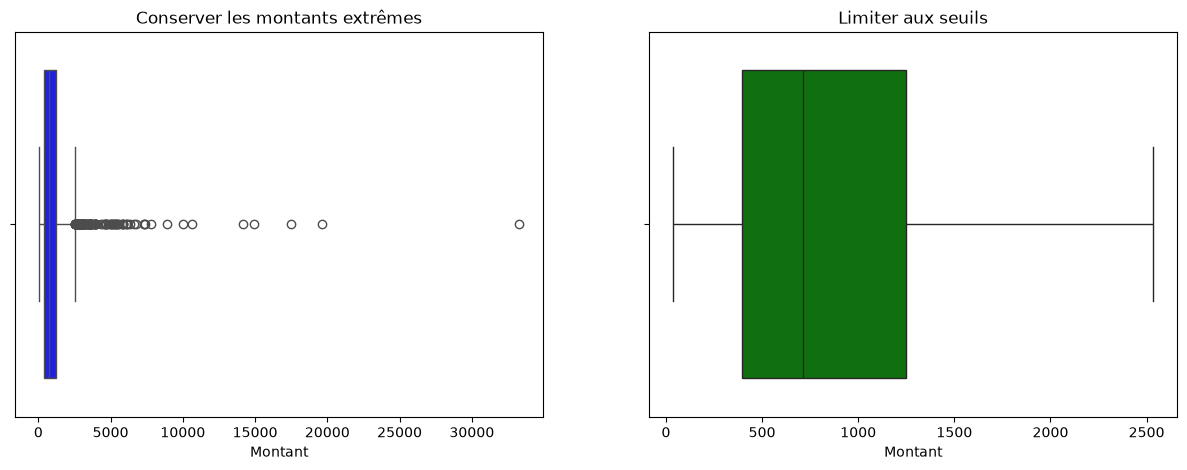

In [57]:
X_conserver = X_ref.copy()
X_limiter = X_ref.copy()
X_limiter["montant_dh"] = np.clip(X_limiter["montant_dh"], L, U)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x = X_conserver["montant_dh"], ax = axes[0], color = "blue")
axes[0].set_title("Conserver les montants extrêmes")
axes[0].set_xlabel("Montant")

sns.boxplot(x = X_limiter["montant_dh"], ax = axes[1], color = "green")
axes[1].set_title("Limiter aux seuils")
axes[1].set_xlabel("Montant")

In [58]:
X_ref_dh = X_ref[["montant_dh"]]
X_ver_dh = X_ver[["montant_dh"]]

minmax_scaler = MinMaxScaler()
minmax_scaler.fit(X_ref_dh)
dh_ref_minmax = minmax_scaler.transform(X_ref_dh)
dh_ver_minmax = minmax_scaler.transform(X_ver_dh)

standardScaler = StandardScaler()
standardScaler.fit(X_ref_dh)
dh_ref_standard = standardScaler.transform(X_ref_dh)
dh_ver_standard = standardScaler.transform(X_ver_dh)

robustScaler = RobustScaler()
robustScaler.fit(X_ref_dh)
dh_ref_robust = robustScaler.transform(X_ref_dh)
dh_ver_robust = robustScaler.transform(X_ver_dh)

In [59]:
val1 = X_ref["montant_dh"].quantile(0.1)
val2 = X_ref["montant_dh"].quantile(0.25)
val3 = X_ref["montant_dh"].quantile(0.5)
valmax = X_ref["montant_dh"].max()

tableau_NorExtreme = pd.DataFrame({
    "Valeurs": ["val1", "val2", "val3", "valmax"],
    "montant_dh": [val1, val2, val3, valmax]
})
tableau_NorExtreme["MinMax"] = minmax_scaler.transform(tableau_NorExtreme[["montant_dh"]])
tableau_NorExtreme["Standard"] = standardScaler.transform(tableau_NorExtreme[["montant_dh"]])
tableau_NorExtreme["Robust"] = robustScaler.transform(tableau_NorExtreme[["montant_dh"]])
print(tableau_NorExtreme)

  Valeurs  montant_dh    MinMax   Standard     Robust
0    val1     236.468  0.006018  -0.589083  -0.553608
1    val2     393.095  0.010729  -0.473170  -0.370800
2    val3     710.790  0.020285  -0.238059   0.000000
3  valmax   33281.230  1.000000  23.865830  38.014829


Text(0.5, 0, 'Valeur transformée')

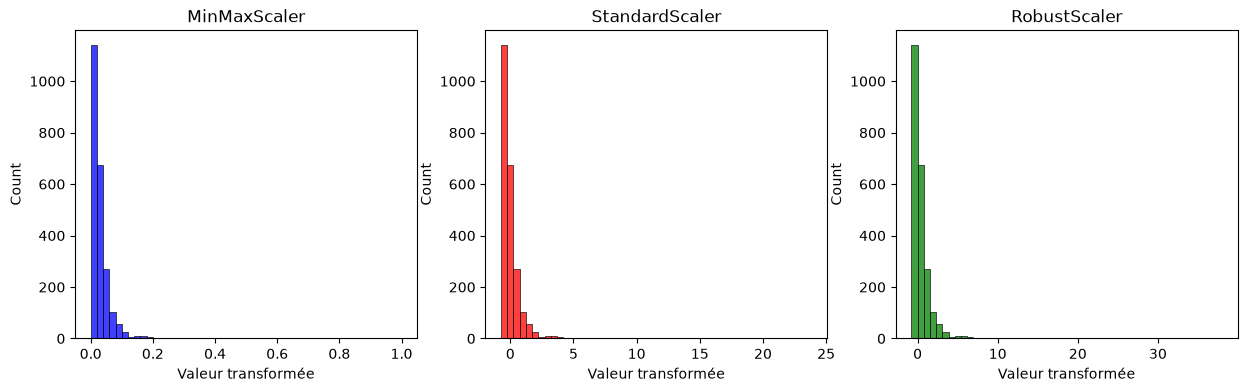

In [60]:
fig, axes = plt.subplots(1, 3, figsize = (15, 4))
sns.histplot(dh_ref_minmax.flatten(), bins = 50, ax = axes[0], color = "blue")
axes[0].set_title("MinMaxScaler")
axes[0].set_xlabel("Valeur transformée")

sns.histplot(dh_ref_standard.flatten(), bins = 50, ax = axes[1], color = "red")
axes[1].set_title("StandardScaler")
axes[1].set_xlabel("Valeur transformée")

sns.histplot(dh_ref_robust.flatten(), bins = 50, ax = axes[2], color = "green")
axes[2].set_title("RobustScaler")
axes[2].set_xlabel("Valeur transformée")

In [68]:
X_ref_exemple = np.array([[20], [50], [80]])
Mscaler = MinMaxScaler()
Mscaler.fit(X_ref_exemple)

nouvelle_transaction = np.array([[100]])
valeur_transformee = Mscaler.transform(nouvelle_transaction)

print(f"Valeur originale : {nouvelle_transaction[0][0]}")
print(f"Valeur transformée : {valeur_transformee[0][0]}")

Valeur originale : 100
Valeur transformée : 1.3333333333333335


In [69]:
#partie4
compte_classes = y_ref.value_counts()
print("Nombre de lignes par classe :\n", compte_classes)
nb_normal = compte_classes[0]
nb_fraude = compte_classes[1]

rapport = nb_normal / nb_fraude
print(f"\nIl y a {nb_normal} transactions normales pour {nb_fraude} fraudes.")
print(f"Le rapport est : {rapport}")

Nombre de lignes par classe :
 fraude
0    2194
1     206
Name: count, dtype: int64

Il y a 2194 transactions normales pour 206 fraudes.
Le rapport est : 10.650485436893204


In [70]:
print("Avant RandomOverSampler")
print(y_ref.value_counts())
ROS = RandomOverSampler(random_state=42)
X_ref_Roversampled, y_ref_Roversampled = ROS.fit_resample(X_ref, y_ref)
print("\nAprès RandomOverSampler")
print(y_ref_Roversampled.value_counts())

Avant RandomOverSampler
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomOverSampler
fraude
0    2194
1    2194
Name: count, dtype: int64


In [71]:
print("Avant RandomUnderSampler")
print(y_ref.value_counts())
RUS = RandomUnderSampler(random_state=42)
X_ref_undersampled, y_ref_undersampled = RUS.fit_resample(X_ref, y_ref)

print("\nAprès RandomUnderSampler")
print(y_ref_undersampled.value_counts())

Avant RandomUnderSampler
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomUnderSampler
fraude
0    206
1    206
Name: count, dtype: int64


In [72]:
X_mini = pd.DataFrame({
    "Var1": [10, 20, 30, 15, 25, 100],
    "Var2": [1, 2, 3, 1.5, 7.2, 10]
})
y_mini = pd.Series([0, 0, 0, 1, 1, 0])
print("Données réelles")
print(X_mini[y_mini == 1])

smote = SMOTE(sampling_strategy = {1: 4}, k_neighbors = 1, random_state = 42)
X_res, y_res = smote.fit_resample(X_mini, y_mini)
print("\nDonnées après SMOTE")
df_resultat = pd.DataFrame(X_res, columns = ["Var1", "Var2"])
df_resultat["Classe"] = y_res
print(df_resultat[df_resultat["Classe"] == 1])

Données réelles
   Var1  Var2
3    15   1.5
4    25   7.2

Données après SMOTE
   Var1      Var2  Classe
3    15  1.500000       1
4    25  7.200000       1
6    24  6.919072       1
7    17  3.027635       1


In [73]:
initial = y_ref.value_counts()
over = y_ref_Roversampled.value_counts()
under = y_ref_undersampled.value_counts()
donnees_tableau = {
    "Étape": ["Avant rééquilibrage", "Après RandomOverSampler", "Après RandomUnderSampler"],
    "0 = normale" : [
        initial.get(0, 0),
        over.get(0, 0),
        under.get(0, 0)
    ],
    "1 = Fraudes" : [
        initial.get(1, 0),
        over.get(1, 0),
        under.get(1, 0)
    ]
}
effectifs = pd.DataFrame(donnees_tableau)
effectifs["Somme"] = effectifs["0 = normale"] + effectifs["1 = Fraudes"]
print("Tableau des effectifs des classes :\n")
print(effectifs.to_string(index = False))

Tableau des effectifs des classes :

                   Étape  0 = normale  1 = Fraudes  Somme
     Avant rééquilibrage         2194          206   2400
 Après RandomOverSampler         2194         2194   4388
Après RandomUnderSampler          206          206    412


In [74]:
# partie 5
pipeline_numer_final = Pipeline(steps = [
    ("imputation_mediane", SimpleImputer(strategy = "median")),
    ("robust_scaler", RobustScaler())
])
pipeline_categ_final = Pipeline(steps = [
    ("imputation_frequent", SimpleImputer(strategy = "most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown = "ignore"))
])
preprocesseur_final = ColumnTransformer(
    transformers = [
        ("numer", pipeline_numer_final, colonnes_numeriques),
        ("categ", pipeline_categ_final, colonnes_categorielles)
    ]
)

In [75]:
X_ref_final = preprocesseur_final.fit_transform(X_ref)
X_ver_final = preprocesseur_final.transform(X_ver)

print("\nVérification de nombre de colonnes")
print(f"- Nombre de colonnes de groupe de référence final : {X_ref_final.shape[1]}")
print(f"- Nombre de colonnes de groupe de vérification final : {X_ver_final.shape[1]}")

print("\nVérification des valeurs manquantes")
nb_nan_ref = pd.isnull(X_ref_final).sum()
nb_nan_ver = pd.isnull(X_ver_final).sum()
print(f"- Nombre de NaN dans le groupe de référence final : {nb_nan_ref}")
print(f"- Nombre de NaN dans le groupe de vérification final : {nb_nan_ver}")



Vérification de nombre de colonnes
- Nombre de colonnes de groupe de référence final : 18
- Nombre de colonnes de groupe de vérification final : 18

Vérification des valeurs manquantes
- Nombre de NaN dans le groupe de référence final : 0
- Nombre de NaN dans le groupe de vérification final : 0


In [76]:
nouvelle_categorie = X_ver.iloc[[0]].copy()
nouvelle_categorie["canal"] = "Canal_Inconnu"
print("Catégories connues dans X_ref :", X_ref["canal"].unique())
print("\nCatégorie simulée :", nouvelle_categorie["canal"].values[0])
try:
    resultat = preprocesseur_final.transform(nouvelle_categorie)
    print("\nSuccès : Le préprocesseur a transformé la ligne sans erreur.")
except Exception as e:
    print("\nErreur :", e)

Catégories connues dans X_ref : <StringArray>
['application', 'site_web', 'agence', 'telephone', nan]
Length: 5, dtype: str

Catégorie simulée : Canal_Inconnu

Succès : Le préprocesseur a transformé la ligne sans erreur.


In [77]:
import joblib
joblib_fichier = "preprocesseur_final.joblib"
joblib.dump(preprocesseur_final, joblib_fichier)

preprocesseur_recharge = joblib.load(joblib_fichier)

echantillon = X_ver.iloc[:3]
resultat_original = preprocesseur_final.transform(echantillon)
resultat_recharge = preprocesseur_recharge.transform(echantillon)
est_identique = np.allclose(resultat_original, resultat_recharge)

if est_identique:
    print("Vérification réussie (les mêmes valeurs).")
else:
    print("Erreur : Les valeurs sont différents.")

Vérification réussie (les mêmes valeurs).


In [82]:
#Bonus A
bonus_montant = X_ref[["montant_dh"]].copy()
moyenne = bonus_montant["montant_dh"].mean()
mediane = bonus_montant["montant_dh"].median()
print(f"Moyenne : {moyenne} DH")
print(f"Médiane : {mediane} DH")

montant_avec_nan = bonus_montant.copy()
montant_avec_nan.loc[0, "montant_dh"] = np.nan
val_imputee_moyenne = SimpleImputer(strategy = "mean").fit_transform(montant_avec_nan)[0][0]
val_imputee_mediane = SimpleImputer(strategy = "median").fit_transform(montant_avec_nan)[0][0]

print("\nValeur inventée pour remplacer le NaN")
print(f"Imputation par la moyenne : {val_imputee_moyenne:.2f} DH")
print(f"Imputation par la médiane : {val_imputee_mediane:.2f} DH")

montant_avec_outlier = bonus_montant.copy()
montant_avec_outlier.loc[1, "montant_dh"] = 100000 
montant_avec_outlier.loc[0, "montant_dh"] = np.nan

nouvelle_moyenne = montant_avec_outlier["montant_dh"].mean()
nouvelle_mediane = montant_avec_outlier["montant_dh"].median()

print("\nImpact d'un montant de 100 000 DH")
print(f"Nouvelle moyenne : {nouvelle_moyenne:.2f} DH")
print(f"Nouvelle médiane : {nouvelle_mediane:.2f} DH")

Moyenne : 1032.467776816609 DH
Médiane : 710.79 DH

Valeur inventée pour remplacer le NaN
Imputation par la moyenne : 419.53 DH
Imputation par la médiane : 419.53 DH

Impact d'un montant de 100 000 DH
Nouvelle moyenne : 1073.39 DH
Nouvelle médiane : 710.79 DH


In [83]:
#Bonus B
from imblearn.over_sampling import SMOTENC
X_mixte = pd.DataFrame({
    "montant": [100, 150, 120, 500, 550, 2000],
    "canal":   [0,   1,   0,   2,   2,   1]
})
y_mixte = pd.Series([0, 0, 0, 1, 1, 0]) 

print("Données originales")
print(X_mixte[y_mixte == 1])

smote_classique = SMOTE(k_neighbors = 1, random_state = 42)
X_smote, y_smote = smote_classique.fit_resample(X_mixte, y_mixte)

print("\nSMOTE")
print(pd.DataFrame(X_smote, columns = ["montant", "canal"]).iloc[-2:]) 

smote_nc = SMOTENC(categorical_features = [1], k_neighbors = 1, random_state = 42)
X_smotenc, y_smotenc = smote_nc.fit_resample(X_mixte, y_mixte)

print("\nSMOTENC")
print(pd.DataFrame(X_smotenc, columns = ["montant", "canal"]).iloc[-2:])

Données originales
   montant  canal
3      500      2
4      550      2

SMOTE
   montant  canal
6      547      2
7      513      2

SMOTENC
   montant  canal
6      547      2
7      513      2
